<a href="https://colab.research.google.com/github/M-Roshan0708/-Cars-Dataset-EDA-Project/blob/main/M_ROSHAN_EDA_MinorProject2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving AB_NYC_2019.csv to AB_NYC_2019 (1).csv
Saving New_York_City_.png to New_York_City_ (1).png


In [ ]:
# Importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the dataset
df = pd.read_csv('AB_NYC_2019.csv')

# Display first five rows
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
print("Dataset Loaded Successfully!")
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Dataset Loaded Successfully!
Shape: (48895, 16)
Rows: 48895
Columns: 16


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [ ]:
# Identifying numerical columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Identifying categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical Columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [ ]:
# Calculate missing values
missing_values = df.isnull().sum()

# Calculate missing percentages
missing_percentage = (missing_values / len(df)) * 100

# Create missing values report
missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage.round(2)
})

print(missing_report)

                                Missing Values  Missing Percentage
id                                           0                0.00
name                                        16                0.03
host_id                                      0                0.00
host_name                                   21                0.04
neighbourhood_group                          0                0.00
neighbourhood                                0                0.00
latitude                                     0                0.00
longitude                                    0                0.00
room_type                                    0                0.00
price                                        0                0.00
minimum_nights                               0                0.00
number_of_reviews                            0                0.00
last_review                              10052               20.56
reviews_per_month                        10052               2

In [ ]:
# Checking missing values in last_review

print("Missing values in last_review:",
      df['last_review'].isnull().sum())

print("Missing percentage:",
      (df['last_review'].isnull().sum() / len(df)) * 100)

Missing values in last_review: 10052
Missing percentage: 20.55833929849678


In [ ]:
# Dropping last_review column

df.drop(columns=['last_review'], inplace=True)

print("last_review column successfully removed!")

last_review column successfully removed!


In [ ]:
# Investigating missing reviews_per_month values

missing_reviews = df[df['reviews_per_month'].isnull()]

print("Missing reviews_per_month:",
      len(missing_reviews))

print("\nNumber of reviews in these records:")

print(missing_reviews['number_of_reviews'].value_counts())

Missing reviews_per_month: 10052

Number of reviews in these records:
number_of_reviews
0    10052
Name: count, dtype: int64


In [ ]:
# Filling missing values with 0

df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

print("Missing values successfully replaced with 0!")

Missing values successfully replaced with 0!


In [ ]:
# Removing irrelevant identifier columns

columns_to_drop = [
    'id',
    'name',
    'host_id',
    'host_name'
]

df.drop(columns=columns_to_drop, inplace=True)

print("Irrelevant columns successfully removed!")

Irrelevant columns successfully removed!


In [ ]:
# Checking the cleaned dataset

print("CLEANED DATASET INFORMATION")
print("-" * 40)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nRemaining Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

CLEANED DATASET INFORMATION
----------------------------------------
Total Rows: 48895
Total Columns: 11

Remaining Columns:
['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Missing Values:
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  --

In [ ]:
# Statistical analysis of price and minimum_nights

print("PRICE STATISTICS")
print(df['price'].describe())

print("\nMINIMUM NIGHTS STATISTICS")
print(df['minimum_nights'].describe())

PRICE STATISTICS
count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

MINIMUM NIGHTS STATISTICS
count    48895.000000
mean         7.029962
std         20.510550
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
max       1250.000000
Name: minimum_nights, dtype: float64


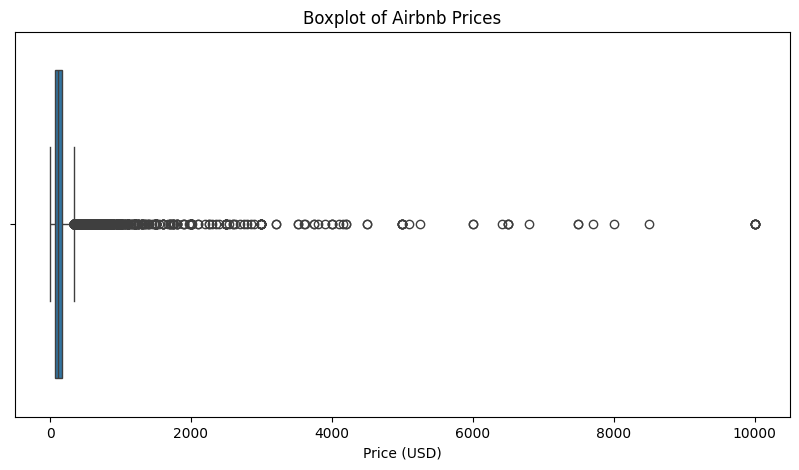

In [ ]:
# Boxplot for Airbnb Prices

plt.figure(figsize=(10, 5))

sns.boxplot(x=df['price'])

plt.title("Boxplot of Airbnb Prices")
plt.xlabel("Price (USD)")

plt.show()

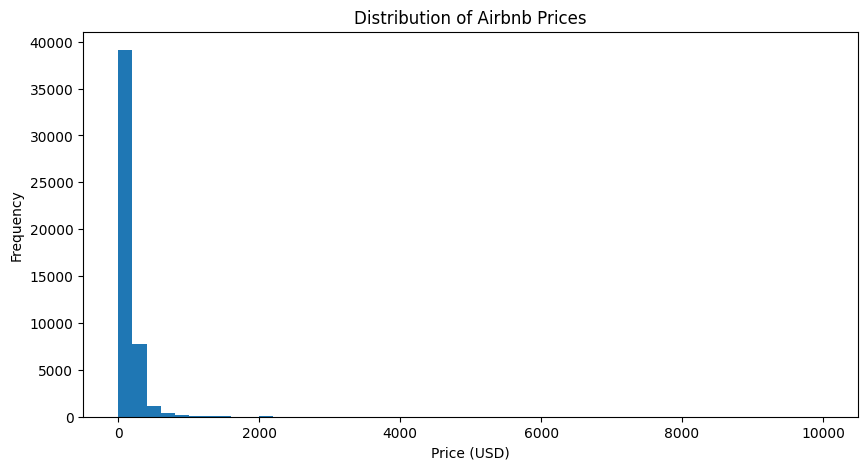

In [ ]:
# Price Distribution

plt.figure(figsize=(10, 5))

plt.hist(df['price'], bins=50)

plt.title("Distribution of Airbnb Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")

plt.show()

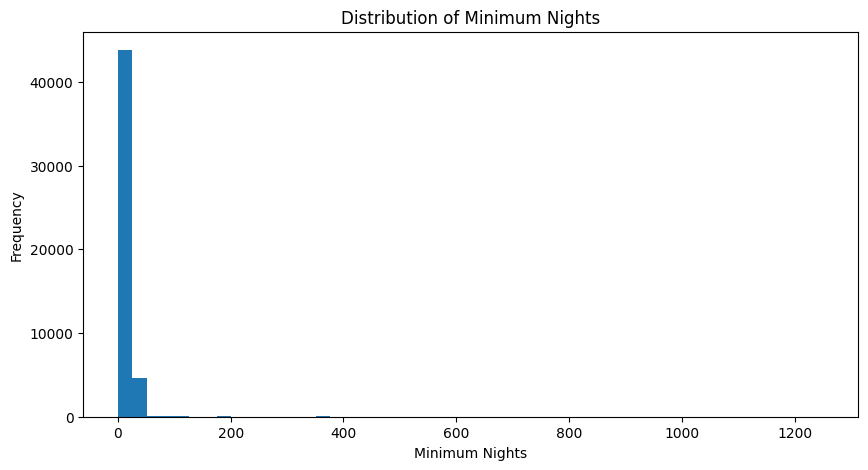

In [ ]:
# Minimum Nights Distribution

plt.figure(figsize=(10, 5))

plt.hist(df['minimum_nights'], bins=50)

plt.title("Distribution of Minimum Nights")
plt.xlabel("Minimum Nights")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# Calculating 95th percentile

price_95 = df['price'].quantile(0.95)

nights_95 = df['minimum_nights'].quantile(0.95)

print("95th Percentile of Price:", price_95)

print("95th Percentile of Minimum Nights:", nights_95)

95th Percentile of Price: 355.0
95th Percentile of Minimum Nights: 30.0


In [ ]:
# Creating a separate cleaned dataset

df_clean = df.copy()

# Removing extreme values using 95th percentile

df_clean = df_clean[
    (df_clean['price'] <= price_95) &
    (df_clean['minimum_nights'] <= nights_95)
]

print("Outlier Treatment Completed!")

Outlier Treatment Completed!


In [ ]:
# Comparing dataset before and after outlier removal

print("BEFORE OUTLIER TREATMENT")
print("Rows:", df.shape[0])

print("\nAFTER OUTLIER TREATMENT")
print("Rows:", df_clean.shape[0])

print("\nTOTAL ROWS REMOVED:")
print(df.shape[0] - df_clean.shape[0])

BEFORE OUTLIER TREATMENT
Rows: 48895

AFTER OUTLIER TREATMENT
Rows: 45759

TOTAL ROWS REMOVED:
3136


In [ ]:
# Verifying the cleaned dataset

print("Maximum Price:",
      df_clean['price'].max())

print("Maximum Minimum Nights:",
      df_clean['minimum_nights'].max())

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum().sum())

Maximum Price: 355
Maximum Minimum Nights: 30

Remaining Missing Values:
0


In [ ]:
# Checking unique values in categorical columns

print("Unique Neighbourhoods:",
      df_clean['neighbourhood'].nunique())

print("Unique Neighbourhood Groups:",
      df_clean['neighbourhood_group'].nunique())

print("Unique Room Types:",
      df_clean['room_type'].nunique())

Unique Neighbourhoods: 219
Unique Neighbourhood Groups: 5
Unique Room Types: 3


In [ ]:
# Dropping high cardinality column

df_clean.drop(columns=['neighbourhood'], inplace=True)

print("Neighbourhood column successfully removed!")

print("\nRemaining Columns:")
print(df_clean.columns.tolist())

Neighbourhood column successfully removed!

Remaining Columns:
['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [ ]:
# Applying One-Hot Encoding

df_clean = pd.get_dummies(
    df_clean,
    columns=['neighbourhood_group', 'room_type'],
    drop_first=True,
    dtype=int
)

print("One-Hot Encoding Successfully Completed!")

One-Hot Encoding Successfully Completed!


In [ ]:
# Displaying the updated dataset

print("Updated Dataset Shape:", df_clean.shape)

print("\nUpdated Columns:")

print(df_clean.columns.tolist())

print("\nFirst Five Rows:")

df_clean.head()

Updated Dataset Shape: (45759, 14)

Updated Columns:
['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']

First Five Rows:


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0


In [ ]:
# Checking whether categorical columns remain

print("Remaining Object Columns:")

print(df_clean.select_dtypes(
    include=['object']
).columns.tolist())

print("\nMissing Values:",
      df_clean.isnull().sum().sum())

print("\nFinal Dataset Shape:",
      df_clean.shape)

Remaining Object Columns:
[]

Missing Values: 0

Final Dataset Shape: (45759, 14)


In [ ]:
print("Current Dataset Columns:")
print(df_clean.columns.tolist())

Current Dataset Columns:
['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']


In [ ]:
expected_columns = [
    'neighbourhood_group_Brooklyn',
    'neighbourhood_group_Manhattan',
    'neighbourhood_group_Queens',
    'neighbourhood_group_Staten Island',
    'room_type_Private room',
    'room_type_Shared room'
]

for col in expected_columns:
    print(col, ":", col in df_clean.columns)

neighbourhood_group_Brooklyn : True
neighbourhood_group_Manhattan : True
neighbourhood_group_Queens : True
neighbourhood_group_Staten Island : True
room_type_Private room : True
room_type_Shared room : True


In [ ]:
# Separating features and target variable

X = df_clean.drop('price', axis=1)

y = df_clean['price']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (45759, 13)
Target Shape: (45759,)


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Splitting dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training and Testing Split Completed!")

Training and Testing Split Completed!


In [ ]:
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (36607, 13)
X_test Shape: (9152, 13)
y_train Shape: (36607,)
y_test Shape: (9152,)


In [ ]:
print("Training Percentage:",
      (len(X_train) / len(X)) * 100)

print("Testing Percentage:",
      (len(X_test) / len(X)) * 100)

Training Percentage: 79.99956292751152
Testing Percentage: 20.000437072488474


In [ ]:
# Importing Linear Regression

from sklearn.linear_model import LinearRegression

# Importing evaluation metrics

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [ ]:
# Initializing Linear Regression Model

model = LinearRegression()

print("Linear Regression Model Initialized Successfully!")

Linear Regression Model Initialized Successfully!


In [ ]:
# Training the Linear Regression Model

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [ ]:
# Predicting Airbnb Prices

y_pred = model.predict(X_test)

print("Price Prediction Completed Successfully!")

print("\nFirst 10 Predicted Prices:")
print(y_pred[:10])

Price Prediction Completed Successfully!

First 10 Predicted Prices:
[173.31999192 157.35088508 173.11463763 182.65747453 186.31011596
 165.57173509 128.75527424  59.73992377 191.65680481  99.05073498]


In [ ]:
# Comparing Actual and Predicted Prices

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0           132       173.319992
1           250       157.350885
2           350       173.114638
3           250       182.657475
4           199       186.310116
5           139       165.571735
6           150       128.755274
7            55        59.739924
8           184       191.656805
9           129        99.050735


In [ ]:
# Evaluating the Linear Regression Model

r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

# Displaying Results

print("MODEL EVALUATION RESULTS")
print("-" * 40)

print("R2 Score:", round(r2, 4))

print("Mean Absolute Error (MAE):", round(mae, 2))

print("Mean Squared Error (MSE):", round(mse, 2))

print("Root Mean Squared Error (RMSE):", round(rmse, 2))

MODEL EVALUATION RESULTS
----------------------------------------
R2 Score: 0.4708
Mean Absolute Error (MAE): 38.54
Mean Squared Error (MSE): 2834.96
Root Mean Squared Error (RMSE): 53.24


In [ ]:
# Creating Model Evaluation Summary

evaluation_results = pd.DataFrame({
    'Evaluation Metric': [
        'R2 Score',
        'MAE',
        'MSE',
        'RMSE'
    ],

    'Result': [
        r2,
        mae,
        mse,
        rmse
    ]
})

print(evaluation_results)

  Evaluation Metric       Result
0          R2 Score     0.470828
1               MAE    38.540875
2               MSE  2834.959379
3              RMSE    53.244337


In [ ]:
y_pred = model.predict(X_test)

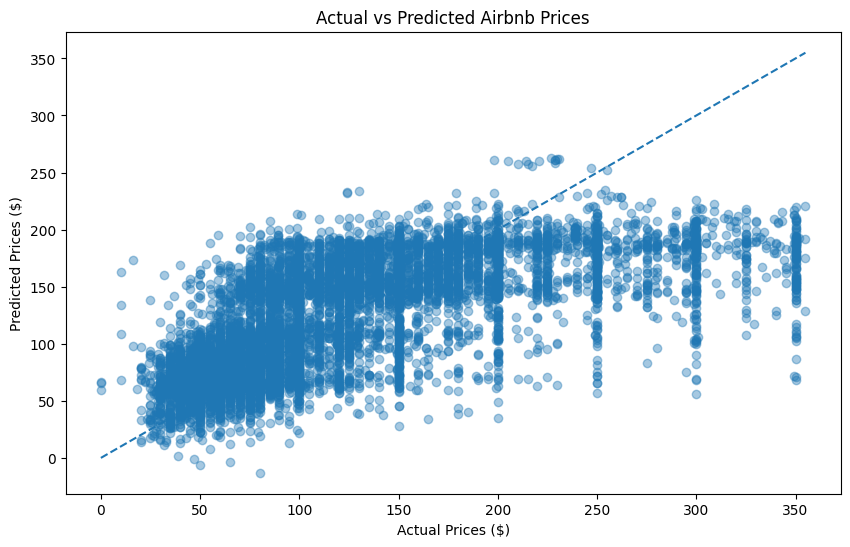

In [ ]:
# Task 7.1: Actual Prices vs Predicted Prices

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

# Perfect prediction line (45-degree diagonal)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Prices ($)")
plt.ylabel("Predicted Prices ($)")

plt.title("Actual vs Predicted Airbnb Prices")

plt.show()

In [ ]:
# Task 7.2: Calculating Residuals

residuals = y_test - y_pred

print("Residual Calculation Completed!")

print("\nFirst 10 Residual Values:")
print(residuals.head(10))

Residual Calculation Completed!

First 10 Residual Values:
15403    -41.319992
25339     92.649115
17177    176.885362
39544     67.342525
16658     12.689884
27465    -26.571735
16740     21.244726
25369     -4.739924
32889     -7.656805
30769     29.949265
Name: price, dtype: float64


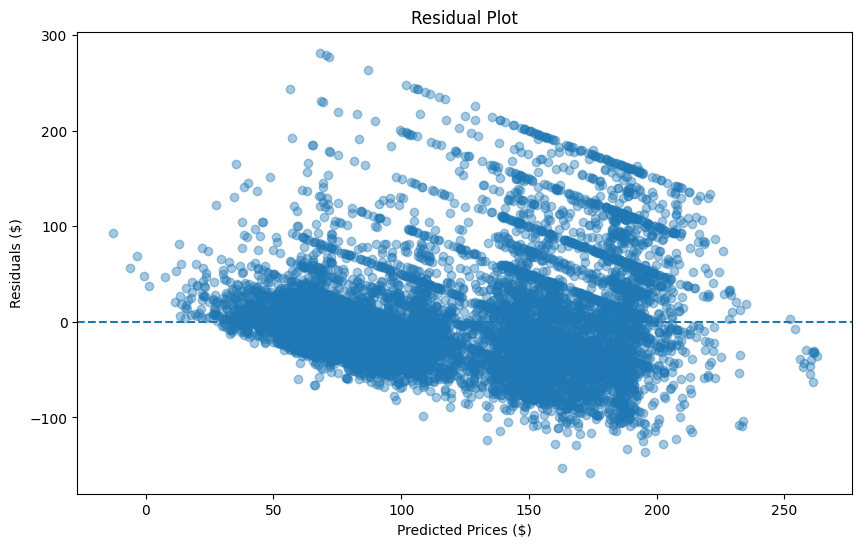

In [ ]:
# Residual Plot: Errors vs Predicted Values

plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, alpha=0.4)

# Zero error reference line

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Prices ($)")
plt.ylabel("Residuals ($)")

plt.title("Residual Plot")

plt.show()

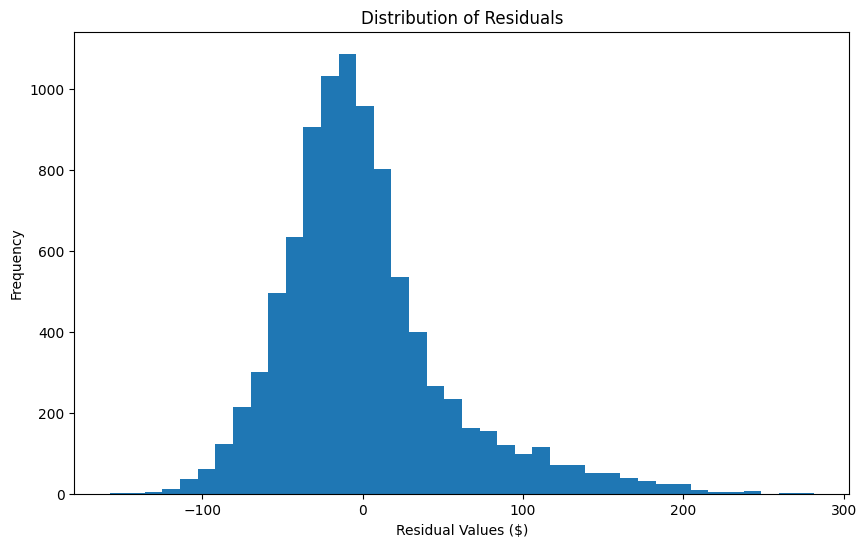

In [ ]:
# Residual Distribution Histogram

plt.figure(figsize=(10, 6))

plt.hist(residuals, bins=40)

plt.xlabel("Residual Values ($)")
plt.ylabel("Frequency")

plt.title("Distribution of Residuals")

plt.show()

In [ ]:
# Task 7.3: Comparing Prediction Errors

comparison_df = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison_df['Absolute Error'] = abs(
    comparison_df['Actual Price'] -
    comparison_df['Predicted Price']
)

# Divide listings using median actual price

median_price = comparison_df['Actual Price'].median()

cheap_listings = comparison_df[
    comparison_df['Actual Price'] <= median_price
]

expensive_listings = comparison_df[
    comparison_df['Actual Price'] > median_price
]

# Calculate MAE for both groups

cheap_mae = cheap_listings['Absolute Error'].mean()

expensive_mae = expensive_listings['Absolute Error'].mean()

print("MEDIAN PRICE:", median_price)

print("\nCHEAP LISTINGS")
print("Records:", len(cheap_listings))
print("MAE:", round(cheap_mae, 2))

print("\nEXPENSIVE LISTINGS")
print("Records:", len(expensive_listings))
print("MAE:", round(expensive_mae, 2))

MEDIAN PRICE: 100.0

CHEAP LISTINGS
Records: 4699
MAE: 29.03

EXPENSIVE LISTINGS
Records: 4453
MAE: 48.58


In [ ]:
# Comparing Cheap and Expensive Listings

price_comparison = pd.DataFrame({
    'Category': ['Cheap Listings', 'Expensive Listings'],
    'Number of Listings': [
        len(cheap_listings),
        len(expensive_listings)
    ],
    'MAE': [
        cheap_mae,
        expensive_mae
    ]
})

print(price_comparison)

             Category  Number of Listings        MAE
0      Cheap Listings                4699  29.027664
1  Expensive Listings                4453  48.579631


In [ ]:
residuals = y_test - y_pred